# Segmentación de una nube de puntos industrial mediante clustering
A continuación se listan los pasos del flujo completo para segmentar `FARO_Scan_Full_Sub1_down3_with_normals.ply` en ocho clases.

| Paso | Acción | Técnica |
|---|---|---|
| 1 | Carga y exploración | resolución, atributos, normales |
| 2 | Eliminación de ruido | vecinos por radio |
| 3 | Submuestreo | vóxeles de 10 cm |
| 4 | Descriptores locales | PCA local multiescala, color HSV |
| 5 | Niveles de altura | GMM (BIC, silhouette) |
| 6 | Superficies horizontales conexas | DBSCAN (curva k-distancia) |
| 7 | Suelo, cubierta y plataforma | reglas por nivel, crecimiento de regiones |
| 8 | Tipos geométricos | k-means (silhouette, DB, CH) |
| 9 | Instancias | DBSCAN por tipo |
| 10 | Segmentos mixtos | clustering espectral (eigengap) |
| 11 | Clases de los segmentos | Ward (dendrograma, DB) |
| 12 | Refinamiento y propagación | orientación, filtro de moda, kNN |
| 13 | Exportación | PLY y capturas 3D |

## Configuración

In [1]:
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from matplotlib.colors import rgb_to_hsv
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import laplacian
from scipy.sparse.linalg import eigsh
from scipy.spatial import cKDTree
from scipy.stats import mode, norm
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", module="sklearn.neighbors")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

DATA = "data/FARO_Scan_Full_Sub1_down3_with_normals.ply"

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
@dataclass
class Cloud:
    xyz: np.ndarray
    rgb: np.ndarray
    normals: np.ndarray

    def __len__(self):
        return len(self.xyz)

    def subset(self, mask):
        return Cloud(self.xyz[mask], self.rgb[mask], self.normals[mask])


def load_cloud(path):
    pc = o3d.io.read_point_cloud(path)
    return Cloud(np.asarray(pc.points), np.asarray(pc.colors), np.asarray(pc.normals))


def save_colored_ply(path, xyz, colors):
    pc = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(xyz))
    pc.colors = o3d.utility.Vector3dVector(np.clip(colors, 0, 1))
    o3d.io.write_point_cloud(path, pc)


VIEWS = {"xz": (0, 2, 1, -1), "yz": (1, 2, 0, 1), "xy": (0, 1, 2, 1)}


def view(ax, xyz, c, plane="xz", s=0.2, title="", **kw):
    a, b, depth, sign = VIEWS[plane]
    o = np.argsort(sign * xyz[:, depth])
    sc = ax.scatter(xyz[o, a], xyz[o, b], c=c if isinstance(c, str) else c[o], s=s, **kw)
    ax.set(aspect="equal", title=title, xlabel=f"{plane[0]} [m]", ylabel=f"{plane[1]} [m]")
    return sc


def save_fig(name, **kw):
    plt.tight_layout(**kw)
    plt.savefig(f"figures/{name}.png")
    plt.show()

## 1. Carga y exploración de la nube

In [3]:
cloud = load_cloud(DATA)
print(f"Puntos: {len(cloud):,}")

Puntos: 1,647,021


In [4]:
attrs = np.hstack([cloud.xyz, cloud.rgb, cloud.normals])
cols = ["x", "y", "z", "r", "g", "b", "nx", "ny", "nz"]
pd.DataFrame(attrs, columns=cols).describe().round(3)

,x,y,z,r,g,b,nx,ny,nz
count,1647021.000,1647021.000,1647021.000,1647021.000,1647021.000,1647021.000,1647021.000,1647021.000,1647021.000
mean,10.911,4.695,2.367,0.450,0.442,0.431,0.011,-0.031,0.123
std,7.303,8.535,3.918,0.252,0.274,0.269,0.485,0.446,0.741
min,-2.582,-11.874,-2.311,0.000,0.000,0.000,-1.000,-1.000,-1.000
25%,4.676,-2.094,-1.447,0.243,0.200,0.192,-0.042,-0.081,-0.482
50%,10.371,4.807,1.354,0.396,0.396,0.376,0.001,-0.003,0.008
75%,16.748,11.140,5.670,0.584,0.608,0.596,0.068,0.057,0.998
max,28.803,22.994,14.459,1.000,1.000,1.000,1.000,1.000,1.000


La escena ocupa unos 31 × 35 m en planta y 17 m de alto.

### Resolución

Distancia al vecino 1 (p5 / p50 / p95): [0.0318 0.0336 0.0396]
Distancia al vecino 10 (p5 / p50 / p95): [0.062  0.0712 0.0918]


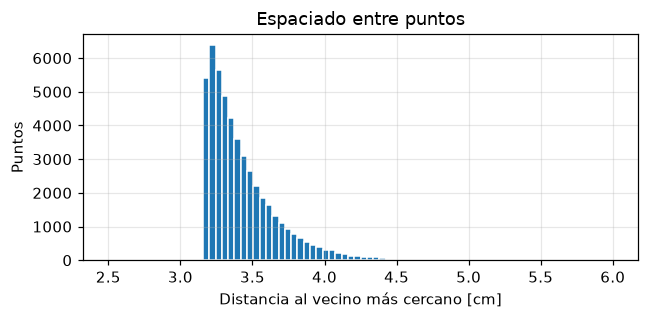

In [5]:
rng = np.random.default_rng(0)
sample = rng.choice(len(cloud), 50_000, replace=False)
dist, _ = cKDTree(cloud.xyz).query(cloud.xyz[sample], k=11)
for k in (1, 10):
    print(f"Distancia al vecino {k} (p5 / p50 / p95):", np.percentile(dist[:, k], [5, 50, 95]).round(4))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(dist[:, 1] * 100, bins=80, range=(2.5, 6), edgecolor="white")
ax.set(xlabel="Distancia al vecino más cercano [cm]", ylabel="Puntos", title="Espaciado entre puntos")
ax.grid(alpha=0.3)
save_fig("fig01_spacing")

Espaciado casi uniforme de unos 3.3 cm: un único radio o `eps` sirve para toda la escena.

### Distribución de los atributos

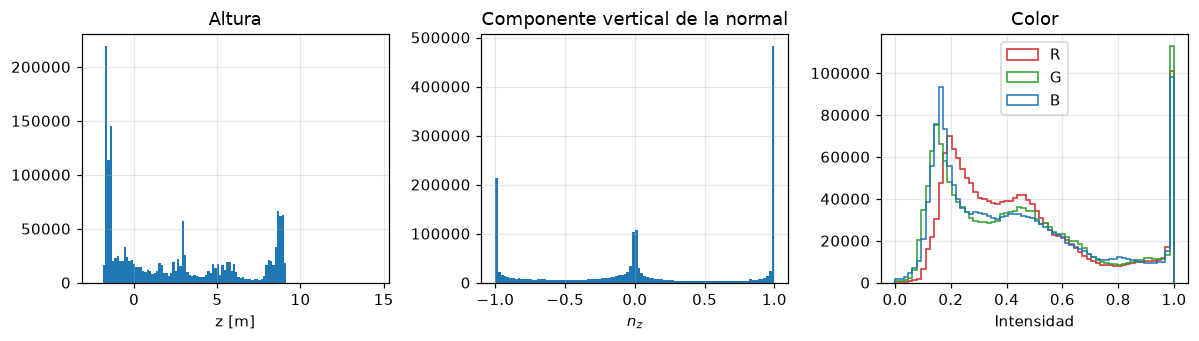

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].hist(cloud.xyz[:, 2], bins=120)
axes[0].set(xlabel="z [m]", title="Altura")
axes[1].hist(cloud.normals[:, 2], bins=100)
axes[1].set(xlabel="$n_z$", title="Componente vertical de la normal")
for i, c in enumerate(["tab:red", "tab:green", "tab:blue"]):
    axes[2].hist(cloud.rgb[:, i], bins=64, histtype="step", color=c, label="RGB"[i])
axes[2].set(xlabel="Intensidad", title="Color")
axes[2].legend()
for ax in axes:
    ax.grid(alpha=0.3)
save_fig("fig01_attributes")

La altura muestra niveles horizontales (suelo, plataforma a 2.9 m y cubierta a 8.6–9 m), $n_z$ se concentra en $\pm 1$ y 0, y el color es mayormente gris, con vigas verdes y algunas tuberías de color.

### Orientación de las normales

In [7]:
horizontal = np.abs(cloud.normals[:, 2]) > 0.9
floor = horizontal & (cloud.xyz[:, 2] < -1)
roof = horizontal & (cloud.xyz[:, 2] > 7.5)

print(f"Piso:  {(cloud.normals[floor, 2] > 0).mean():.1%} de las normales apuntan hacia arriba")
print(f"Cubierta: {(cloud.normals[roof, 2] < 0).mean():.1%} de las normales apuntan hacia abajo")

Piso:  99.8% de las normales apuntan hacia arriba
Cubierta: 99.5% de las normales apuntan hacia abajo


Las normales apuntan hacia el escáner, así que el signo de $n_z$ distingue caras superiores de inferiores.

### Vistas de la escena

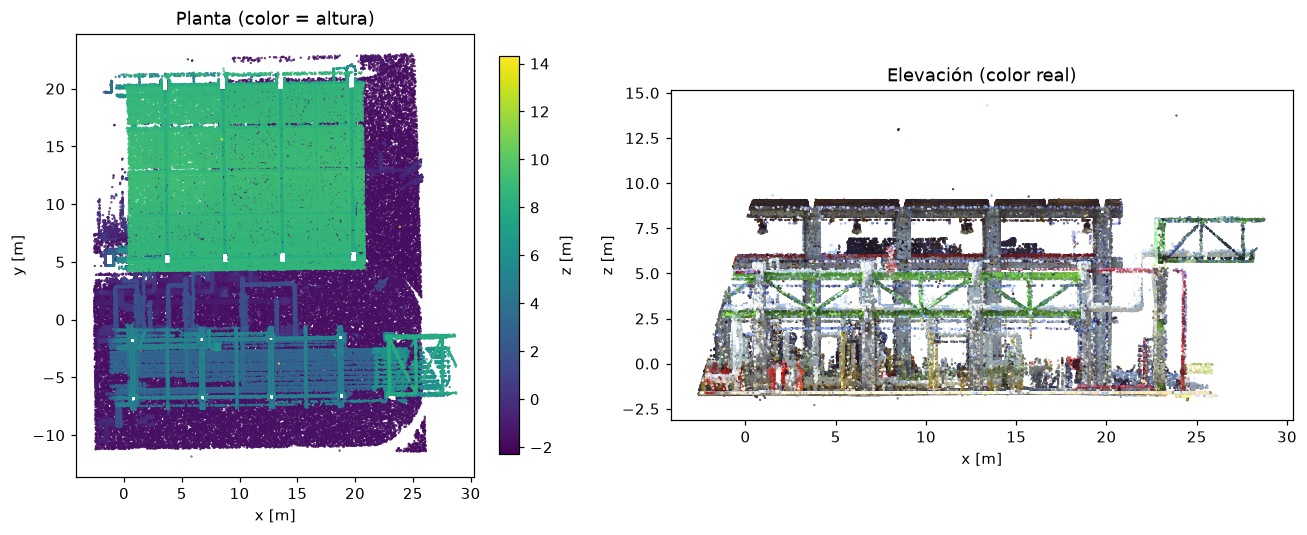

In [8]:
sub = rng.choice(len(cloud), 300_000, replace=False)
xyz, rgb = cloud.xyz[sub], cloud.rgb[sub]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.25]})
sc = view(axes[0], xyz, xyz[:, 2], "xy", title="Planta (color = altura)", cmap="viridis")
fig.colorbar(sc, ax=axes[0], label="z [m]", shrink=0.8)
view(axes[1], xyz, rgb, "xz", title="Elevación (color real)")
save_fig("fig01_views")

## 2. Eliminación de ruido
Ruido: menos de 5 vecinos en un radio de 15 cm.

In [9]:
neighbors = cKDTree(cloud.xyz).query_ball_point(cloud.xyz, 0.15, return_length=True, workers=-1)
noise = neighbors - 1 < 5
print(f"Puntos aislados: {noise.sum():,} ({noise.mean():.2%})")
print("Altura de los puntos aislados (p5 / p50 / p95):", np.percentile(cloud.xyz[noise, 2], [5, 50, 95]).round(2))

Puntos aislados: 2,811 (0.17%)
Altura de los puntos aislados (p5 / p50 / p95): [-1.45  0.66  7.92]


## 3. Submuestreo por vóxeles

In [10]:
def voxel_downsample(cloud, voxel_size):
    keys = np.floor(cloud.xyz / voxel_size).astype(np.int64)
    _, inverse, counts = np.unique(keys, axis=0, return_inverse=True, return_counts=True)
    inverse = inverse.ravel()

    def mean_per_voxel(values):
        out = np.zeros((len(counts), values.shape[1]))
        np.add.at(out, inverse, values)
        return out / counts[:, None]

    normals = mean_per_voxel(cloud.normals)
    normals /= np.linalg.norm(normals, axis=1, keepdims=True) + 1e-12
    reduced = Cloud(mean_per_voxel(cloud.xyz), mean_per_voxel(cloud.rgb), normals)
    return reduced, inverse

In [11]:
clean = cloud.subset(~noise)

rows = []
for v in [0.05, 0.08, 0.10, 0.15]:
    reduced, _ = voxel_downsample(clean, v)
    rows.append({"vóxel [m]": v, "puntos": len(reduced), "reducción": f"{len(clean) / len(reduced):.1f}x"})
pd.DataFrame(rows)

,vóxel [m],puntos,reducción
0,0.05,1046268,1.6x
1,0.08,462951,3.6x
2,0.10,308183,5.3x
3,0.15,142191,11.6x


Se usa $v = 10$ cm.

In [12]:
VOXEL = 0.10
reduced, inverse = voxel_downsample(clean, VOXEL)
print(f"Nube de trabajo: {len(reduced):,} puntos")

Nube de trabajo: 308,183 puntos


## 4. Descriptores locales por punto
PCA local en radios de 0.3 y 0.8 m, más $z$, $n_z$, densidad y color HSV (sección II-B del informe).

In [13]:
def local_covariance(xyz, radius, chunk=20_000):
    tree = cKDTree(xyz)
    n = len(xyz)
    cov = np.empty((n, 3, 3))
    counts = np.empty(n, dtype=np.int64)
    for start in range(0, n, chunk):
        stop = min(start + chunk, n)
        neigh = tree.query_ball_point(xyz[start:stop], radius, workers=-1)
        sizes = np.fromiter(map(len, neigh), dtype=np.int64, count=stop - start)
        flat = np.fromiter((j for row in neigh for j in row), dtype=np.int64, count=sizes.sum())
        owner = np.repeat(np.arange(start, stop), sizes)
        q = xyz[flat] - xyz[owner]
        offsets = np.concatenate([[0], np.cumsum(sizes)[:-1]])
        s1 = np.add.reduceat(q, offsets) / sizes[:, None]
        s2 = np.add.reduceat((q[:, :, None] * q[:, None, :]).reshape(-1, 9), offsets).reshape(-1, 3, 3)
        cov[start:stop] = s2 / sizes[:, None, None] - s1[:, :, None] * s1[:, None, :]
        counts[start:stop] = sizes
    return cov, counts


def compute_features(xyz, rgb, normals, radii):
    feats = {"z": xyz[:, 2], "nz": normals[:, 2]}
    for r in radii:
        cov, counts = local_covariance(xyz, r)
        vals, vecs = np.linalg.eigh(cov)
        vals = np.clip(vals[:, ::-1], 0, None)
        l1 = vals[:, 0] + 1e-12
        t = round(r * 100)
        feats |= {
            f"linearity_{t}": (vals[:, 0] - vals[:, 1]) / l1,
            f"planarity_{t}": (vals[:, 1] - vals[:, 2]) / l1,
            f"scattering_{t}": vals[:, 2] / l1,
            f"axis_vertical_{t}": np.abs(vecs[:, 2, 2]),
            f"normal_vertical_{t}": np.abs(vecs[:, 2, 0]),
            f"density_{t}": counts,
        }
    hsv = rgb_to_hsv(np.clip(rgb, 0, 1))
    angle = 2 * np.pi * hsv[:, 0]
    feats |= {
        "chroma_cos": hsv[:, 1] * np.cos(angle),
        "chroma_sin": hsv[:, 1] * np.sin(angle),
        "saturation": hsv[:, 1],
        "value": hsv[:, 2],
    }
    return {k: np.asarray(v, dtype=np.float32) for k, v in feats.items()}

In [14]:
xyz, rgb, normals = reduced.xyz, reduced.rgb, reduced.normals
RADII = [0.3, 0.8]
feats = compute_features(xyz, rgb, normals, RADII)
print(f"{len(xyz):,} puntos, {len(feats)} descriptores:", ", ".join(feats))

308,183 puntos, 18 descriptores: z, nz, linearity_30, planarity_30, scattering_30, axis_vertical_30, normal_vertical_30, density_30, linearity_80, planarity_80, scattering_80, axis_vertical_80, normal_vertical_80, density_80, chroma_cos, chroma_sin, saturation, value


### Dimensionalidad local
(R, G, B) = (linealidad, planaridad, esfericidad) a 0.3 m, sin el suelo.

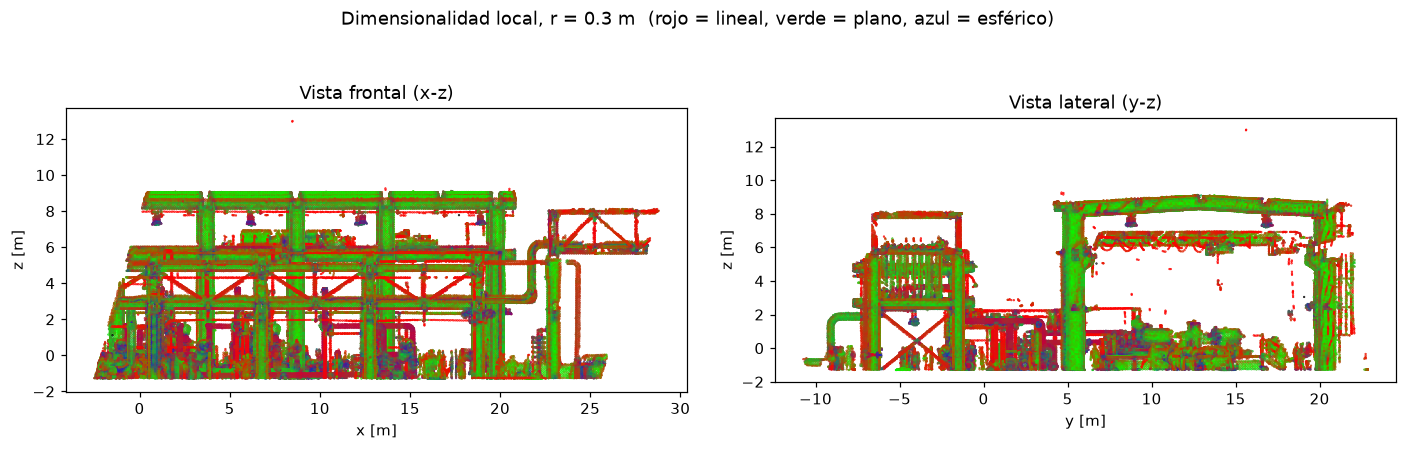

In [15]:
above_ground = xyz[:, 2] > -1.3
dim = np.clip(np.stack([feats["linearity_30"], feats["planarity_30"], feats["scattering_30"]], 1), 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
view(axes[0], xyz[above_ground], dim[above_ground], "xz", title="Vista frontal (x-z)")
view(axes[1], xyz[above_ground], dim[above_ground], "yz", title="Vista lateral (y-z)")
fig.suptitle("Dimensionalidad local, r = 0.3 m  (rojo = lineal, verde = plano, azul = esférico)")
save_fig("fig04_dimensionality")

### Orientación y color

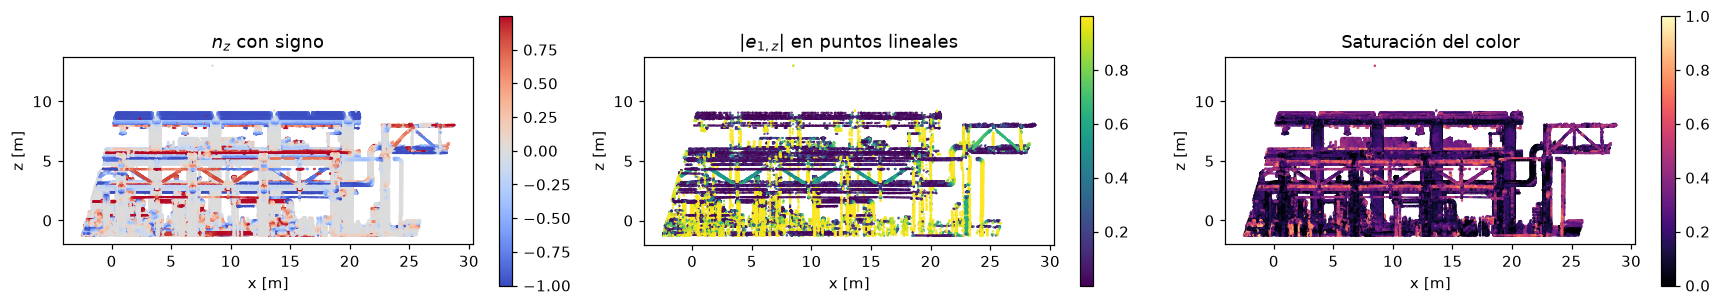

In [16]:
linear = above_ground & (feats["linearity_30"] > 0.6)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, m, key, cmap, title in [
    (axes[0], above_ground, "nz", "coolwarm", "$n_z$ con signo"),
    (axes[1], linear, "axis_vertical_30", "viridis", "$|e_{1,z}|$ en puntos lineales"),
    (axes[2], above_ground, "saturation", "magma", "Saturación del color"),
]:
    sc = view(ax, xyz[m], feats[key][m], "xz", title=title, cmap=cmap)
    fig.colorbar(sc, ax=ax, shrink=0.7)
save_fig("fig04_orientation_color")

### PCA global de los descriptores

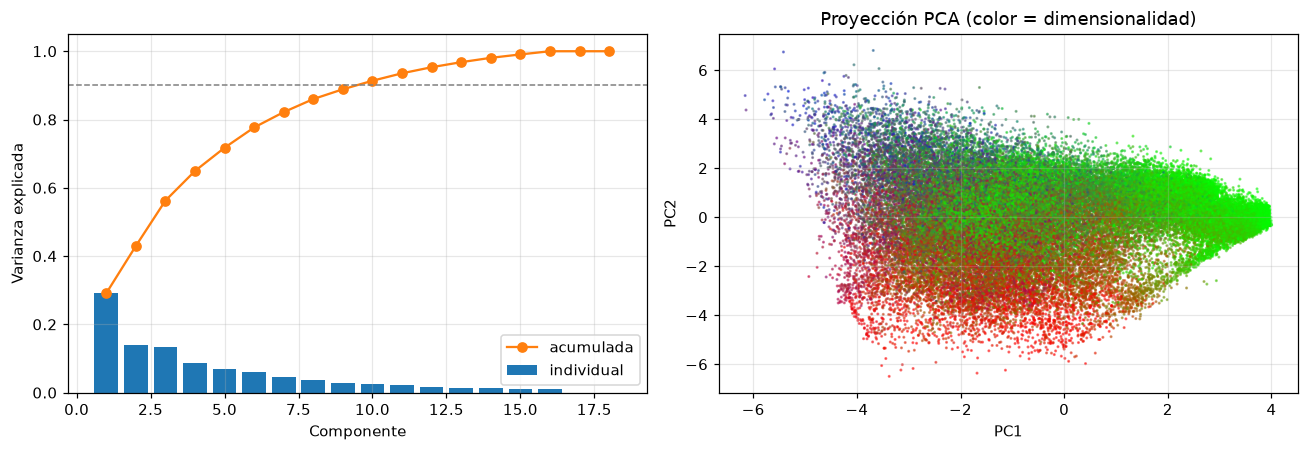

Componentes para 90 % de varianza: 10 de 18


,PC1,PC2,PC3
z,-0.08,0.02,0.47
nz,0.15,-0.08,-0.39
linearity_30,-0.21,-0.38,0.18
planarity_30,0.30,0.20,-0.12
scattering_30,-0.26,0.25,-0.06
axis_vertical_30,-0.30,0.01,-0.11
normal_vertical_30,0.34,0.03,0.09
density_30,-0.17,0.40,-0.14
linearity_80,-0.24,-0.36,0.11
planarity_80,0.37,0.13,-0.04


In [17]:
rng = np.random.default_rng(0)
X = StandardScaler().fit_transform(np.column_stack(list(feats.values())))
pca = PCA().fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
sub = rng.choice(len(X), 60_000, replace=False)
Z = pca.transform(X[sub])[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
comps = range(1, len(cum) + 1)
axes[0].bar(comps, pca.explained_variance_ratio_, label="individual")
axes[0].plot(comps, cum, "o-", color="tab:orange", label="acumulada")
axes[0].axhline(0.9, ls="--", color="gray", lw=1)
axes[0].set(xlabel="Componente", ylabel="Varianza explicada")
axes[0].legend()
axes[1].scatter(Z[:, 0], Z[:, 1], c=dim[sub], s=1, alpha=0.5)
axes[1].set(xlabel="PC1", ylabel="PC2", title="Proyección PCA (color = dimensionalidad)")
for ax in axes:
    ax.grid(alpha=0.3)
save_fig("fig04_pca")

print(f"Componentes para 90 % de varianza: {np.searchsorted(cum, 0.9) + 1} de {len(cum)}")
pd.DataFrame(pca.components_[:3].T, index=list(feats), columns=["PC1", "PC2", "PC3"]).round(2)

## 5. Niveles de altura con GMM

### Candidatos horizontales
$|e_{3,z}| > 0.95$ y planaridad $> 0.5$; el signo de $n_z$ separa las caras hacia arriba y hacia abajo.

In [18]:
xyz = reduced.xyz
f = feats
h = (f["normal_vertical_30"] > 0.95) & (f["planarity_30"] > 0.5)
up = np.where(h & (f["nz"] > 0))[0]
down = np.where(h & (f["nz"] < 0))[0]
print(f"Candidatos horizontales: {h.sum():,} ({h.mean():.1%})")
print(f"  hacia arriba: {len(up):,}   hacia abajo: {len(down):,}")

Candidatos horizontales: 111,113 (36.1%)
  hacia arriba: 77,972   hacia abajo: 33,141


### Selección de $K$

In [19]:
def gmm_model_selection(z, k_range, n_sil=8000, seed=0):
    z = z.reshape(-1, 1)
    sub = z[np.random.default_rng(seed).choice(len(z), min(n_sil, len(z)), replace=False)]
    rows, models = [], {}
    for k in k_range:
        gmm = models[k] = GaussianMixture(k, n_init=5, random_state=seed).fit(z)
        sil = silhouette_score(sub, gmm.predict(sub)) if k > 1 else np.nan
        rows.append({"K": k, "BIC": gmm.bic(z), "AIC": gmm.aic(z), "silhouette": sil})
    return pd.DataFrame(rows).set_index("K"), models

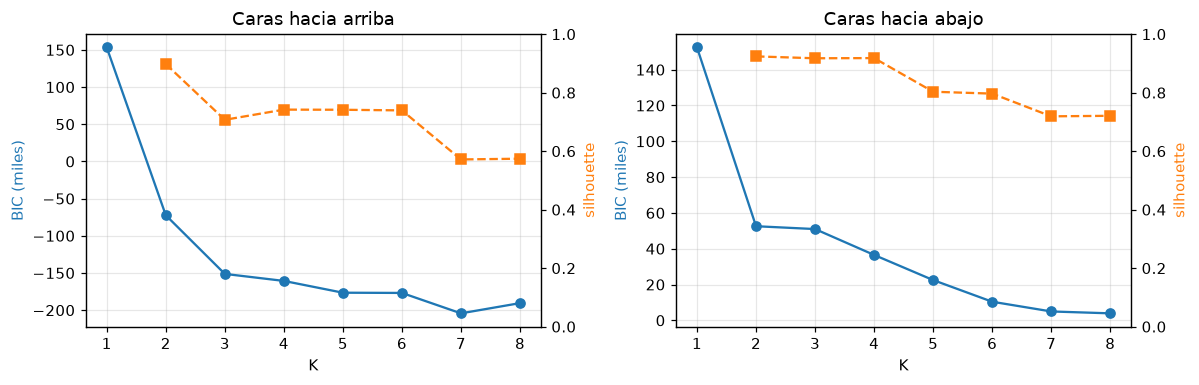

arriba                              abajo                       
          BIC         AIC silhouette         BIC         AIC silhouette
K                                                                      
1  153240.294  153221.766        NaN  152400.601  152383.784        NaN
2  -72359.455  -72405.775      0.898   52560.518   52518.476      0.924
3 -151234.686 -151308.799      0.707   50975.008   50907.740      0.918
4 -160669.266 -160771.171      0.742   36521.813   36429.319      0.918
5 -176524.419 -176654.116      0.742   22484.846   22367.127      0.803
6 -176823.081 -176980.571      0.739   10389.963   10247.018      0.797
7 -204270.841 -204456.123      0.572    4957.152    4788.981      0.719
8 -190518.857 -190731.932      0.574    3902.380    3708.984      0.721

In [20]:
K_RANGE = range(1, 9)
sel_up, models_up = gmm_model_selection(xyz[up, 2], K_RANGE)
sel_down, models_down = gmm_model_selection(xyz[down, 2], K_RANGE)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, sel, title in [(axes[0], sel_up, "Caras hacia arriba"), (axes[1], sel_down, "Caras hacia abajo")]:
    ax.plot(sel.index, sel.BIC / 1e3, "o-")
    ax.set(xlabel="K", title=title)
    ax.set_ylabel("BIC (miles)", color="tab:blue")
    ax.grid(alpha=0.3)
    ax2 = ax.twinx()
    ax2.plot(sel.index, sel.silhouette, "s--", color="tab:orange")
    ax2.set_ylabel("silhouette", color="tab:orange")
    ax2.set_ylim(0, 1)
save_fig("fig05_gmm_selection")

pd.concat({"arriba": sel_up, "abajo": sel_down}, axis=1).round(3)

Se elige $K = 5$ en ambas orientaciones: codo del BIC con silhouette alta.

In [21]:
K_UP, K_DOWN = 5, 5
gmm_up, gmm_down = models_up[K_UP], models_down[K_DOWN]

def describe(gmm):
    o = np.argsort(gmm.means_.ravel())
    return pd.DataFrame({"media z [m]": gmm.means_.ravel()[o],
                         "desv. [m]": np.sqrt(gmm.covariances_.ravel()[o]),
                         "peso": gmm.weights_[o]}).round(3)

display(describe(gmm_up).assign(orientación="arriba"))
display(describe(gmm_down).assign(orientación="abajo"))

,media z [m],desv. [m],peso,orientación
0,-1.650,0.054,0.678,arriba
1,-1.447,0.007,0.249,arriba
2,-0.500,0.006,0.037,arriba
3,-0.380,1.651,0.031,arriba
4,5.900,0.380,0.004,arriba


,media z [m],desv. [m],peso,orientación
0,-0.310,0.750,0.011,abajo
1,2.933,0.178,0.177,abajo
2,5.550,0.650,0.028,abajo
3,8.087,0.112,0.046,abajo
4,8.822,0.134,0.737,abajo


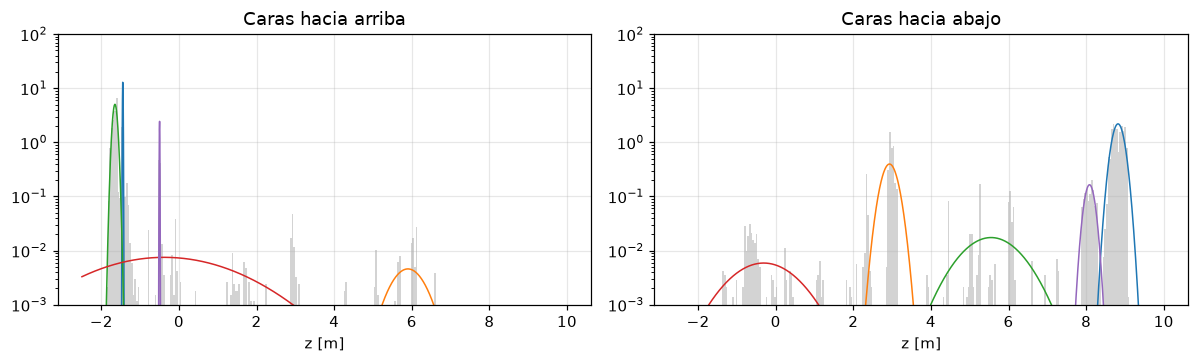

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
grid = np.linspace(-2.5, 10, 2000)
for ax, idx, gmm, title in [(axes[0], up, gmm_up, "Caras hacia arriba"), (axes[1], down, gmm_down, "Caras hacia abajo")]:
    ax.hist(xyz[idx, 2], bins=250, density=True, color="lightgray")
    ax.plot(grid, gmm.weights_ * norm.pdf(grid[:, None], gmm.means_.ravel(), np.sqrt(gmm.covariances_.ravel())), lw=1)
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 1e2)
    ax.set(xlabel="z [m]", title=title)
    ax.grid(alpha=0.3)
save_fig("fig05_gmm_levels")

Componentes de suelo: a menos de 0.5 m del nivel más bajo. Componente de cubierta: la más alta de las caras hacia abajo.

## 6. Superficies horizontales conexas con DBSCAN

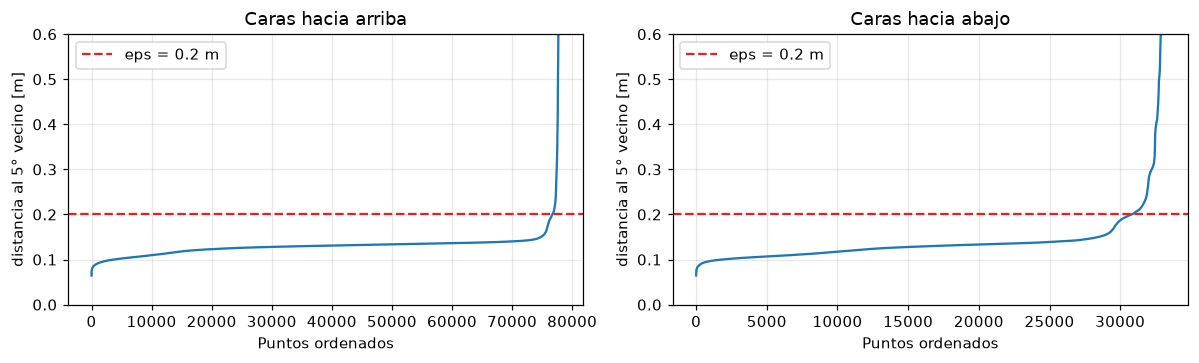

In [23]:
MIN_SAMPLES = 5
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, idx, title in [(axes[0], up, "Caras hacia arriba"), (axes[1], down, "Caras hacia abajo")]:
    d, _ = cKDTree(xyz[idx]).query(xyz[idx], k=MIN_SAMPLES + 1)
    ax.plot(np.sort(d[:, -1]))
    ax.axhline(2 * VOXEL, color="tab:red", ls="--", label=f"eps = {2 * VOXEL:.1f} m")
    ax.set(ylim=(0, 0.6), xlabel="Puntos ordenados", ylabel=f"distancia al {MIN_SAMPLES}° vecino [m]", title=title)
    ax.legend()
    ax.grid(alpha=0.3)
save_fig("fig06_kdistance")

Codo en unos 0.15 m: `eps` = 0.2 m (2 vóxeles).

In [24]:
EPS = 2 * VOXEL
lab_up = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(xyz[up])
lab_down = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(xyz[down])
for name, lab in [("arriba", lab_up), ("abajo", lab_down)]:
    print(f"{name}: {lab.max() + 1} superficies, {np.sum(lab < 0)} puntos de ruido DBSCAN")

patches = pd.DataFrame({"superficie": lab_up, "z": xyz[up, 2]}).query("superficie >= 0")
patches.groupby("superficie").z.agg(n="size", z="median").assign(area_m2=lambda d: d.n * VOXEL**2).nlargest(8, "n").round(2)

arriba: 81 superficies, 475 puntos de ruido DBSCAN
abajo: 183 superficies, 947 puntos de ruido DBSCAN


,n,z,area_m2
superficie,,,
0,43504,-1.62,435.04
1,20353,-1.45,203.53
66,9030,-1.73,90.30
34,1508,-0.50,15.08
21,1337,-0.50,13.37
69,286,-1.33,2.86
67,238,-1.62,2.38
2,161,-0.49,1.61


## 7. Suelo, cubierta y plataforma
A partir de este paso cada punto recibe una clase semántica.

### Clases y colores

In [25]:
CLASSES = {
    "sin_asignar":     (0.80, 0.80, 0.80),
    "ruido":           (0.45, 0.45, 0.45),
    "suelo":           (0.05, 0.15, 0.85),
    "cubierta":        (0.15, 0.55, 0.75),
    "plataforma":      (0.55, 0.35, 0.80),
    "columna":         (0.10, 0.70, 0.20),
    "viga":            (0.95, 0.85, 0.10),
    "tuberia":         (0.90, 0.10, 0.10),
    "arriostramiento": (1.00, 0.50, 0.00),
    "equipo":          (0.60, 0.30, 0.10),
}
NAMES = list(CLASSES)
ID = {name: i for i, name in enumerate(NAMES)}
PALETTE = np.array(list(CLASSES.values()))


def class_table(labels):
    counts = pd.Series(labels).map(dict(enumerate(NAMES))).value_counts()
    return pd.DataFrame({"puntos": counts, "%": (100 * counts / len(labels)).round(1)})


def class_legend(fig, names, **kw):
    handles = [plt.Line2D([], [], ls="", marker="o", color=PALETTE[ID[n]], label=n) for n in names]
    fig.legend(handles=handles, loc="lower center", ncol=len(names), **kw)

### Asignación de clases
Cada superficie toma su nivel GMM mayoritario. Suelo: superficie hacia arriba en una componente de suelo. Cubierta: superficie hacia abajo en la componente de cubierta. Plataforma: otra superficie hacia abajo de más de 5 m².

In [26]:
mu_up, mu_down = gmm_up.means_.ravel(), gmm_down.means_.ravel()
ground_comps = np.where(mu_up < mu_up.min() + 0.5)[0]
roof_comp = np.argmax(mu_down)

level_up = gmm_up.predict(xyz[up, 2:3])
level_down = gmm_down.predict(xyz[down, 2:3])

seeds = {"suelo": [], "cubierta": [], "plataforma": []}
for lab in np.unique(lab_up[lab_up >= 0]):
    m = lab_up == lab
    if np.bincount(level_up[m]).argmax() in ground_comps:
        seeds["suelo"].append(up[m])
for lab in np.unique(lab_down[lab_down >= 0]):
    m = lab_down == lab
    if np.bincount(level_down[m]).argmax() == roof_comp:
        seeds["cubierta"].append(down[m])
    elif m.sum() * VOXEL**2 > 5:
        seeds["plataforma"].append(down[m])

seeds = {k: np.concatenate(v) for k, v in seeds.items()}
{k: len(v) for k, v in seeds.items()}

{'suelo': 73409, 'cubierta': 24264, 'plataforma': 3829}

### Crecimiento de regiones
Suelo: menos de 12 cm sobre la altura local (mediana de las 10 semillas más cercanas en planta). Cubierta y plataforma: menos de 15 cm de una semilla.

In [27]:
def grow_ground(xyz, seeds_xyz, k=10, max_xy_dist=1.0, max_height=0.12):
    dist, idx = cKDTree(seeds_xyz[:, :2]).query(xyz[:, :2], k=k, workers=-1)
    ground_z = np.median(seeds_xyz[idx, 2], axis=1)
    return (dist[:, 0] < max_xy_dist) & (xyz[:, 2] - ground_z < max_height)

In [28]:
label = np.full(len(xyz), ID["sin_asignar"])
label[grow_ground(xyz, xyz[seeds["suelo"]])] = ID["suelo"]
for name in ["cubierta", "plataforma"]:
    near = cKDTree(xyz[seeds[name]]).query(xyz, workers=-1)[0] < 0.15
    label[near & (label == ID["sin_asignar"])] = ID[name]
class_table(label)

,puntos,%
sin_asignar,191248,62.1
suelo,82105,26.6
cubierta,29150,9.5
plataforma,5680,1.8


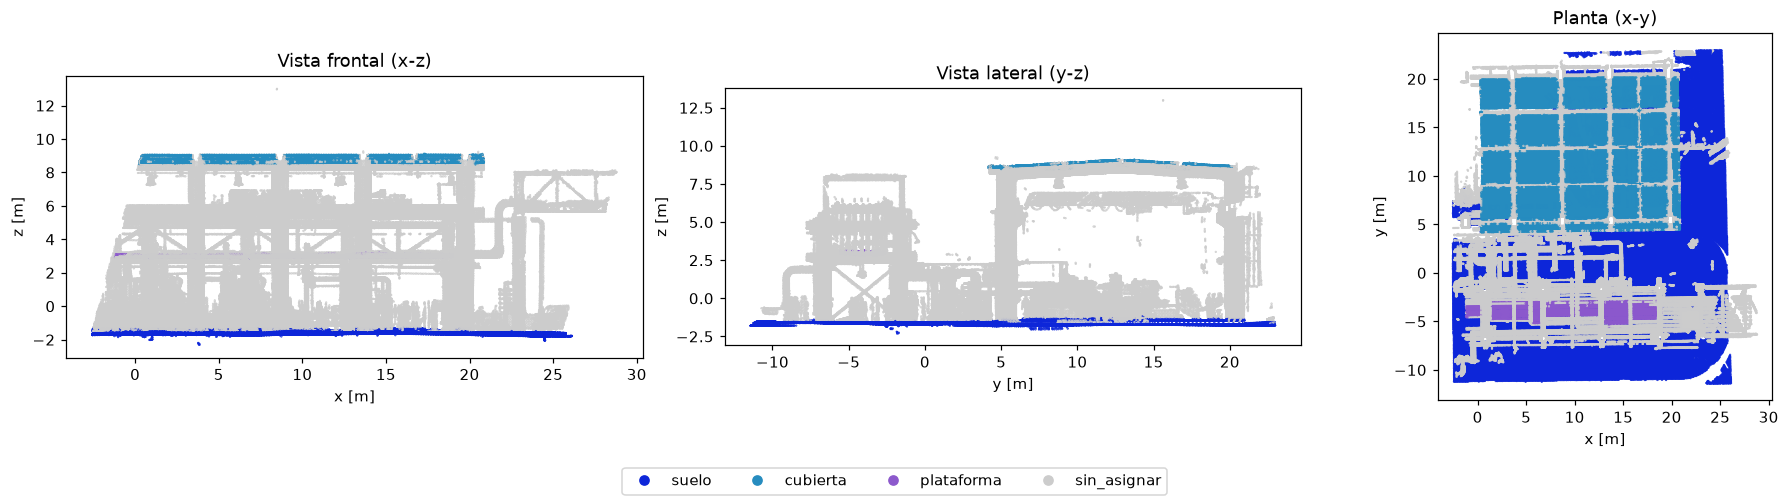

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
for ax, plane, title in zip(axes, ["xz", "yz", "xy"], ["Vista frontal (x-z)", "Vista lateral (y-z)", "Planta (x-y)"]):
    view(ax, xyz, PALETTE[label], plane, title=title)
class_legend(fig, ["suelo", "cubierta", "plataforma", "sin_asignar"])
save_fig("fig07_surfaces", rect=(0, 0.07, 1, 1))

## 8. Tipos geométricos con k-means
La estructura es un solo objeto conexo, así que primero se agrupa por forma local (k-means) y luego por posición dentro de cada forma (DBSCAN, paso 9).

In [30]:
label2 = label.copy()
rest = np.where(label2 == ID["sin_asignar"])[0]
xyz, rgb = reduced.xyz[rest], reduced.rgb[rest]
f = {k: np.asarray(v)[rest] for k, v in feats.items()}
print(f"Puntos a segmentar: {len(rest):,}")

Puntos a segmentar: 191,248


### Selección de $K$

In [31]:
TYPE_FEATURES = [
    "linearity_30", "planarity_30", "scattering_30", "axis_vertical_30",
    "normal_vertical_30", "linearity_80", "scattering_80", "axis_vertical_80",
]


def kmeans_model_selection(X, k_range, n_sil=10_000, seed=0):
    sub = np.random.default_rng(seed).choice(len(X), min(n_sil, len(X)), replace=False)
    rows = []
    for k in k_range:
        labels = KMeans(k, n_init=5, random_state=seed).fit_predict(X)
        rows.append({
            "K": k,
            "silhouette": silhouette_score(X[sub], labels[sub]),
            "davies_bouldin": davies_bouldin_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels),
        })
    return pd.DataFrame(rows).set_index("K")

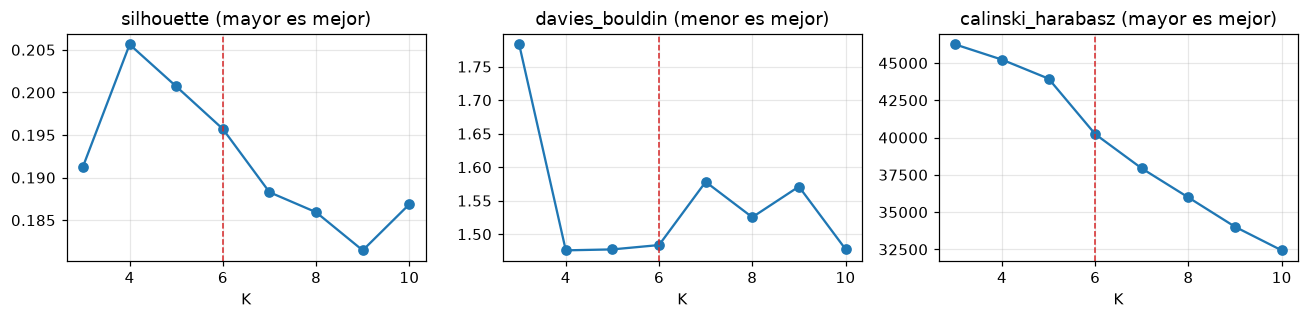

,silhouette,davies_bouldin,calinski_harabasz
K,,,
3,0.191,1.783,46242.794
4,0.206,1.476,45225.335
5,0.201,1.477,43949.089
6,0.196,1.484,40228.265
7,0.188,1.578,37928.250
8,0.186,1.525,35979.547
9,0.181,1.571,34013.752
10,0.187,1.478,32434.327


In [32]:
X = StandardScaler().fit_transform(np.stack([f[c] for c in TYPE_FEATURES], 1))
sel_types = kmeans_model_selection(X, range(3, 11))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col, better in zip(axes, sel_types.columns, ["mayor", "menor", "mayor"]):
    ax.plot(sel_types.index, sel_types[col], "o-")
    ax.axvline(6, color="tab:red", ls="--", lw=1)
    ax.set(title=f"{col} ({better} es mejor)", xlabel="K")
    ax.grid(alpha=0.3)
save_fig("fig08_kmeans_selection")
sel_types.round(3)

Se elige $K = 6$: las métricas apenas difieren de $K = 4$ y los seis tipos son interpretables.

In [33]:
K_TYPES = 6
types = KMeans(K_TYPES, n_init=5, random_state=0).fit_predict(X)

profile = pd.DataFrame({c: f[c] for c in TYPE_FEATURES}).assign(z=xyz[:, 2], tipo=types)
profile = profile.groupby("tipo").mean()
profile["puntos"] = np.bincount(types)
profile.round(2)

,linearity_30,planarity_30,scattering_30,axis_vertical_30,normal_vertical_30,linearity_80,scattering_80,axis_vertical_80,z,puntos
tipo,,,,,,,,,,
0,0.25,0.61,0.14,0.19,0.69,0.42,0.19,0.13,4.19,34517
1,0.67,0.23,0.09,0.13,0.53,0.72,0.09,0.14,3.96,22319
2,0.60,0.28,0.12,0.91,0.09,0.51,0.22,0.83,1.87,28550
3,0.21,0.71,0.08,0.65,0.08,0.30,0.34,0.64,3.28,49947
4,0.62,0.24,0.14,0.16,0.64,0.29,0.29,0.28,3.55,27572
5,0.29,0.31,0.40,0.53,0.38,0.31,0.41,0.52,1.36,28343


In [34]:
TYPE_NAMES = {}
p = profile
for t in p.index:
    lin, pla, sca = p.loc[t, ["linearity_30", "planarity_30", "scattering_30"]]
    axis = p.loc[t, "axis_vertical_80"]
    shape = "esférico" if sca > 0.3 else ("lineal" if lin > pla else "plano")
    orient = "" if shape == "esférico" else (" vertical" if axis > 0.6 else (" diagonal" if axis > 0.2 else " horizontal"))
    TYPE_NAMES[t] = f"{t}: {shape}{orient}"
TYPE_NAMES

{0: '0: plano horizontal',
 1: '1: lineal horizontal',
 2: '2: lineal vertical',
 3: '3: plano vertical',
 4: '4: lineal diagonal',
 5: '5: esférico'}

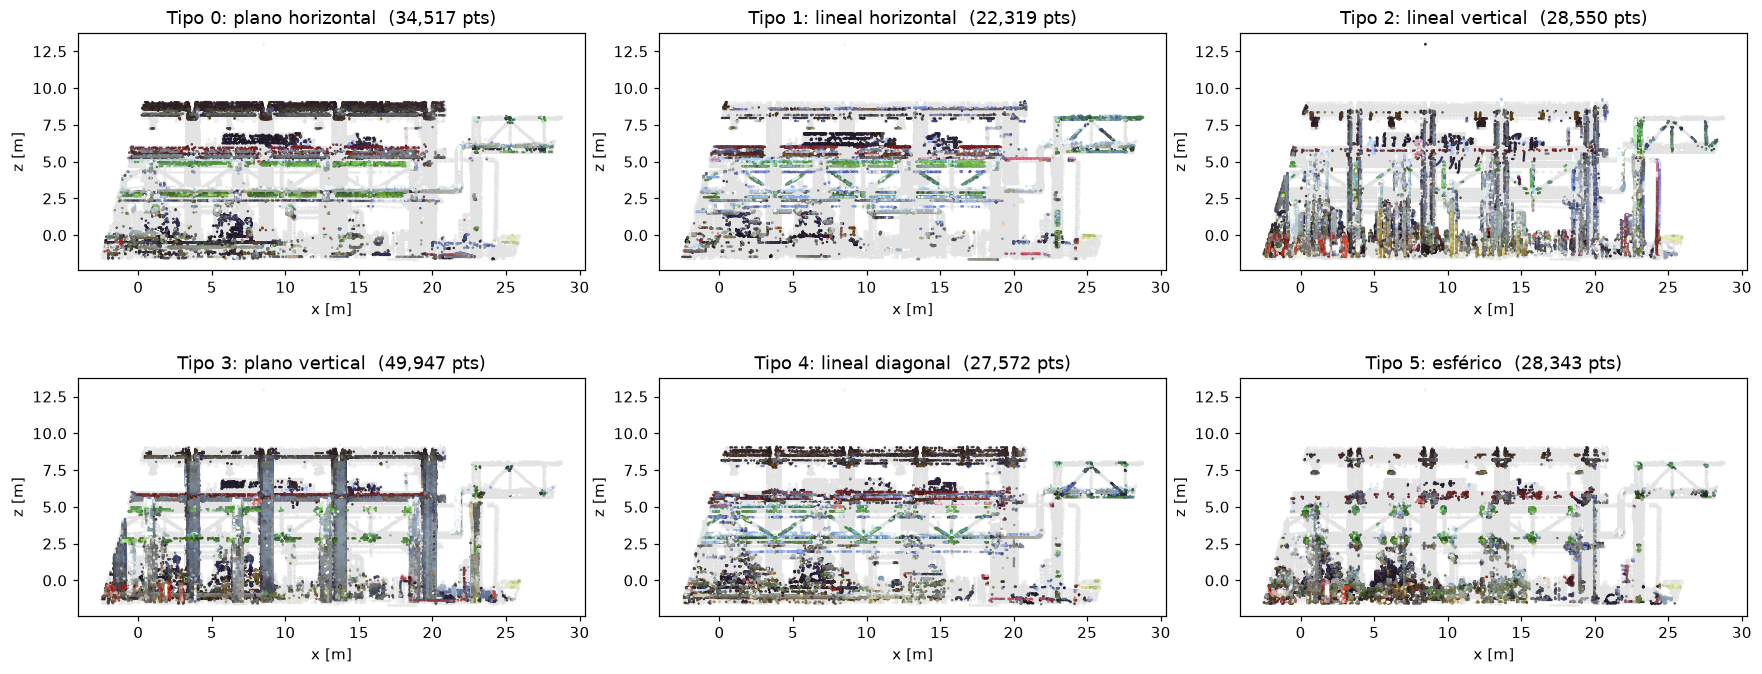

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for t, ax in enumerate(axes.ravel()):
    m = types == t
    view(ax, xyz, "#e3e3e3", s=0.05)
    view(ax, xyz[m], rgb[m], s=0.3, title=f"Tipo {TYPE_NAMES[t]}  ({m.sum():,} pts)")
save_fig("fig08_point_types")

## 9. Segmentación en instancias con DBSCAN
DBSCAN por tipo con `eps` = 0.15 m.

In [36]:
def segment_by_type(xyz, types, eps, min_samples=5):
    seg = np.full(len(xyz), -1)
    next_id = 0
    for t in np.unique(types):
        idx = np.where(types == t)[0]
        lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(xyz[idx])
        ok = lab >= 0
        seg[idx[ok]] = lab[ok] + next_id
        next_id += lab.max() + 1
    return seg

In [37]:
EPS = 0.15
seg = segment_by_type(xyz, types, EPS)
sizes = np.bincount(seg[seg >= 0])
print(f"Segmentos: {len(sizes):,}  |  ruido DBSCAN: {np.sum(seg < 0):,} puntos")

for lo, hi in [(1, 30), (30, 200), (200, 1000), (1000, 10**6)]:
    m = (sizes >= lo) & (sizes < hi)
    print(f"  {lo:>5}-{hi:<7} pts: {m.sum():5d} segmentos, {sizes[m].sum() / len(xyz):5.1%} de los puntos")

Segmentos: 4,564  |  ruido DBSCAN: 22,508 puntos
      1-30      pts:  3610 segmentos, 20.8% de los puntos
     30-200     pts:   858 segmentos, 29.9% de los puntos
    200-1000    pts:    78 segmentos, 15.9% de los puntos
   1000-1000000 pts:    18 segmentos, 21.6% de los puntos


Los segmentos de menos de 30 puntos heredan la clase de sus vecinos en el paso 12.

### Descriptores por segmento

In [38]:
def segment_descriptors(xyz, seg, types, feats, min_points):
    rows = []
    for s in np.unique(seg[seg >= 0]):
        m = seg == s
        if m.sum() < min_points:
            continue
        q = xyz[m]
        centered = q - q.mean(0)
        _, vecs = np.linalg.eigh(centered.T @ centered / len(q))
        extent = np.ptp(centered @ vecs, axis=0)
        rows.append({
            "segment": s,
            "type": types[m][0],
            "n": int(m.sum()),
            "length": extent[2], "width": extent[1], "thickness": extent[0],
            "axis_vertical": abs(vecs[2, 2]),
            "z_min": q[:, 2].min(), "z_max": q[:, 2].max(),
            "normal_vertical": feats["normal_vertical_30"][m].mean(),
            **{c: feats[c][m].mean() for c in ["saturation", "chroma_cos", "chroma_sin", "value"]},
        })
    return pd.DataFrame(rows)

In [39]:
MIN_POINTS = 30
seg_df = segment_descriptors(xyz, seg, types, f, MIN_POINTS)
print(f"Segmentos descritos: {len(seg_df)} ({seg_df.n.sum() / len(xyz):.0%} de los puntos)")

Segmentos descritos: 954 (67% de los puntos)


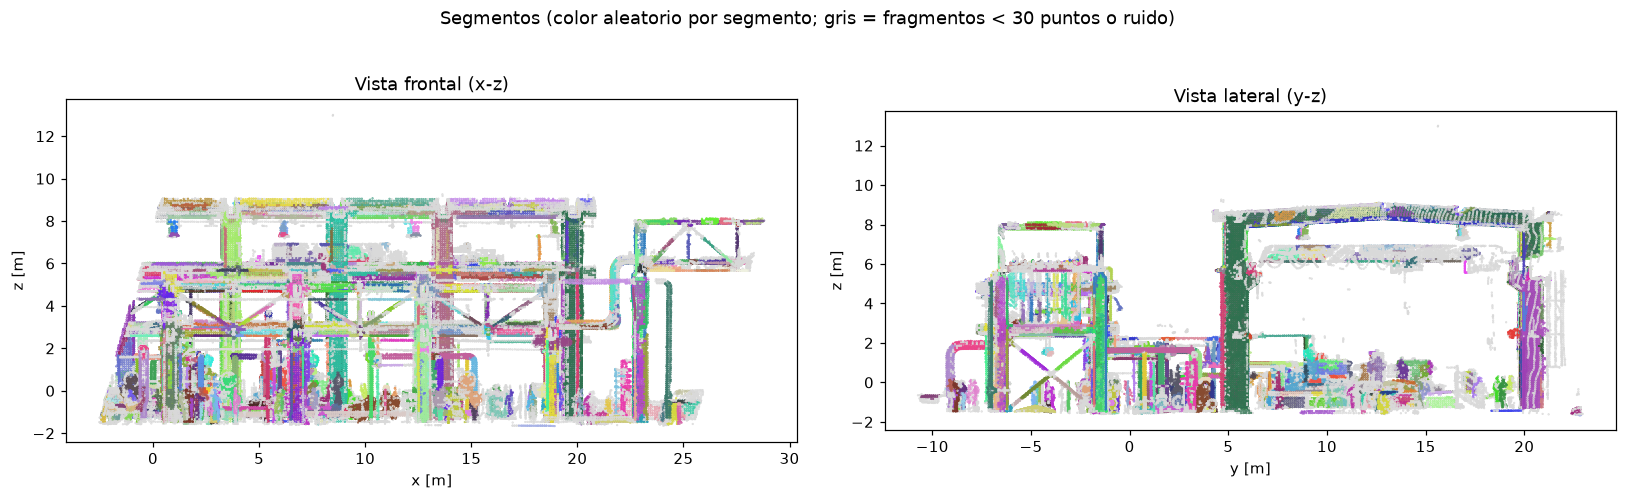

In [40]:
seg_colors = np.random.default_rng(1).uniform(0.15, 0.95, (seg.max() + 1, 3))
colors = np.where(np.isin(seg, seg_df.segment)[:, None], seg_colors[np.maximum(seg, 0)], 0.85)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
view(axes[0], xyz, colors, "xz", title="Vista frontal (x-z)")
view(axes[1], xyz, colors, "yz", title="Vista lateral (y-z)")
fig.suptitle("Segmentos (color aleatorio por segmento; gris = fragmentos < 30 puntos o ruido)")
save_fig("fig09_segments")

## 10. Partición de segmentos mixtos con clustering espectral
Se parten los segmentos de más de 6 m con entre 20 % y 80 % de puntos de eje vertical, sobre un grafo kNN con pesos $w_{ij} = e^{-(\Delta a/0.15)^2}\,e^{-(\Delta n/0.3)^2}$; $k \in \{2, 3, 4\}$ por eigengap.

In [41]:
def orientation_graph(xyz, axis_vertical, normal_vertical, k=12, s_axis=0.15, s_normal=0.3):
    A = kneighbors_graph(xyz, k, include_self=False).tocoo()
    i, j = A.row, A.col
    w = np.exp(-((axis_vertical[i] - axis_vertical[j]) / s_axis) ** 2)
    w *= np.exp(-((normal_vertical[i] - normal_vertical[j]) / s_normal) ** 2)
    W = coo_matrix((w, (i, j)), shape=A.shape).tocsr()
    return 0.5 * (W + W.T)


def eigengap_k(W, k_min=2, k_max=4):
    vals = np.sort(eigsh(laplacian(W, normed=True), k=k_max + 1, sigma=-1e-3,
                         which="LM", return_eigenvectors=False))
    gaps = np.diff(vals)[k_min - 1:k_max]
    return k_min + int(np.argmax(gaps)), vals


def split_segment_spectral(xyz, axis_vertical, normal_vertical, max_points=3000, seed=0):
    rng = np.random.default_rng(seed)
    sub = np.arange(len(xyz)) if len(xyz) <= max_points else rng.choice(len(xyz), max_points, replace=False)
    W = orientation_graph(xyz[sub], axis_vertical[sub], normal_vertical[sub])
    k, vals = eigengap_k(W)
    lab_sub = SpectralClustering(k, affinity="precomputed", random_state=seed,
                                 assign_labels="cluster_qr").fit_predict(W)
    _, nn = cKDTree(xyz[sub]).query(xyz)
    return lab_sub[nn], k, vals

In [42]:
next_id = seg.max() + 1
split_rows, examples = [], []
for _, row in seg_df.iterrows():
    m = np.where(seg == row.segment)[0]
    vertical = np.mean(f["axis_vertical_80"][m] > 0.7)
    if not (row.length > 6 and 0.2 < vertical < 0.8):
        continue
    parts, k, vals = split_segment_spectral(xyz[m], f["axis_vertical_80"][m], f["normal_vertical_30"][m])
    examples.append((m, parts, k, int(row.segment)))
    for c in range(1, k):
        seg[m[parts == c]] = next_id
        next_id += 1
    split_rows.append({"segmento": int(row.segment), "puntos": len(m), "k (eigengap)": k,
                       "autovalores": np.round(vals[:5], 4)})
pd.DataFrame(split_rows)

,segmento,puntos,k (eigengap),autovalores
0,2310,578,3,"[0.0, 0.0, 0.0001, 0.0016, 0.0021]"
1,2405,4646,2,"[-0.0, 0.0, 0.0002, 0.0002, 0.0003]"
2,2443,1621,3,"[0.0, 0.0005, 0.0005, 0.0012, 0.0016]"
3,2495,712,2,"[-0.0, 0.0003, 0.0034, 0.0037, 0.0055]"
4,2553,4976,4,"[0.0, 0.0, 0.0002, 0.0003, 0.0005]"
5,2578,2068,2,"[-0.0, 0.0002, 0.0003, 0.0004, 0.0005]"
6,2603,5235,2,"[-0.0, 0.0, 0.0002, 0.0002, 0.0004]"
7,2613,2014,2,"[0.0, 0.0001, 0.0007, 0.0009, 0.0011]"
8,2644,4228,4,"[-0.0, 0.0, 0.0001, 0.0003, 0.0005]"
9,2688,1065,3,"[-0.0, 0.0002, 0.0005, 0.0028, 0.0039]"


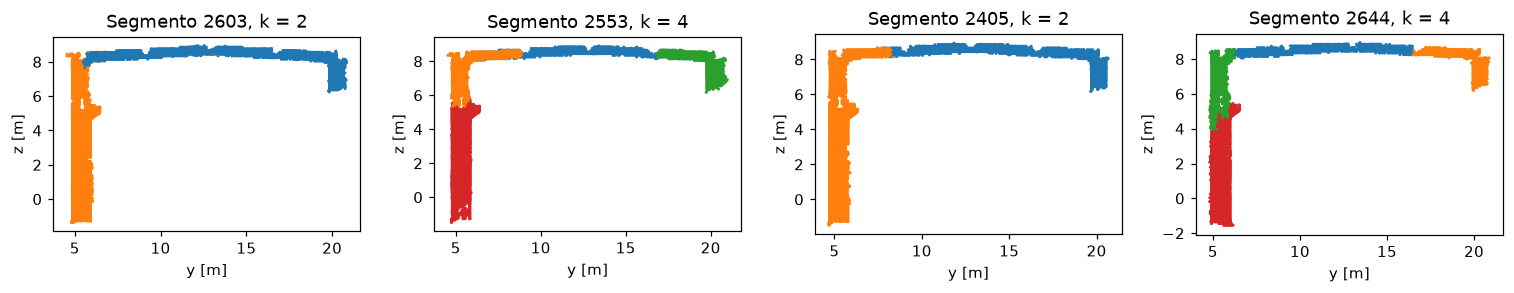

In [43]:
show = sorted(examples, key=lambda e: -len(e[0]))[:4]
fig, axes = plt.subplots(1, 4, figsize=(14, 4.5))
for ax, (m, parts, k, sid) in zip(axes, show):
    plane = "xz" if np.ptp(xyz[m, 0]) > np.ptp(xyz[m, 1]) else "yz"
    view(ax, xyz[m], parts, plane, s=1, title=f"Segmento {sid}, k = {k}", cmap="tab10", vmin=0, vmax=9)
save_fig("fig10_spectral_split")

## 11. Agrupamiento de segmentos con clustering jerárquico
Ward sobre los 12 descriptores estandarizados más el tipo en one-hot.

Segmentos: 971  |  dimensión: 18


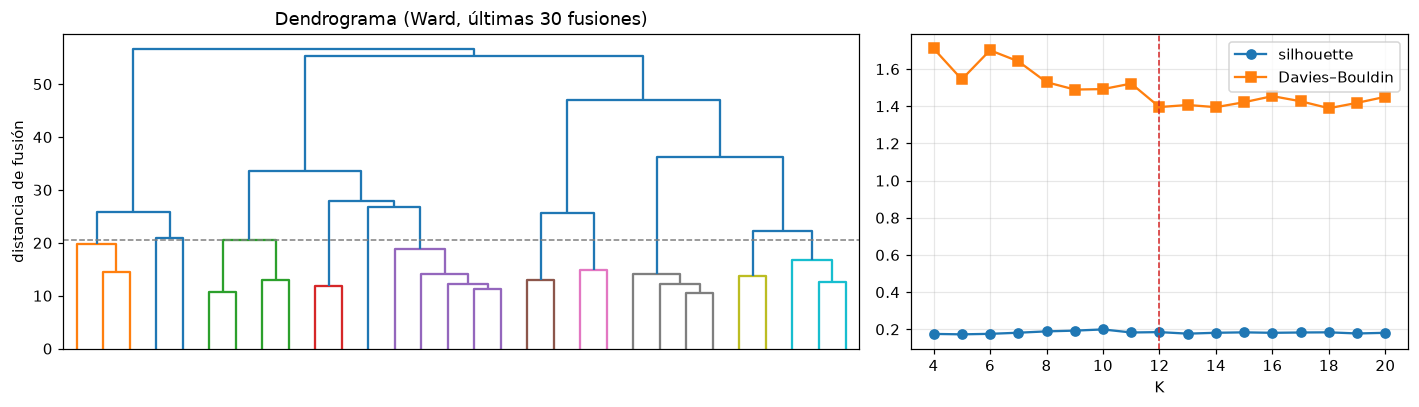

K,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
silhouette,0.175,0.173,0.176,0.182,0.189,0.193,0.199,0.183,0.185,0.177,0.181,0.184,0.181,0.183,0.184,0.178,0.181
davies_bouldin,1.711,1.545,1.701,1.642,1.529,1.490,1.492,1.522,1.396,1.407,1.395,1.422,1.454,1.427,1.389,1.418,1.451


In [44]:
SEGMENT_FEATURES = [
    "log_n", "length", "width", "thickness", "axis_vertical", "z_min", "z_max",
    "normal_vertical", "saturation", "chroma_cos", "chroma_sin", "value",
]
seg_df = segment_descriptors(xyz, seg, types, f, MIN_POINTS)
seg_df["log_n"] = np.log(seg_df.n)
F = np.hstack([StandardScaler().fit_transform(seg_df[SEGMENT_FEATURES]),
               np.eye(types.max() + 1)[seg_df.type]])
print(f"Segmentos: {len(seg_df)}  |  dimensión: {F.shape[1]}")

Z = linkage(F, method="ward")
rows = []
for k in range(4, 21):
    lab = AgglomerativeClustering(k, linkage="ward").fit_predict(F)
    rows.append({"K": k, "silhouette": silhouette_score(F, lab), "davies_bouldin": davies_bouldin_score(F, lab)})
sel_ward = pd.DataFrame(rows).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
dendrogram(Z, truncate_mode="lastp", p=30, ax=axes[0], color_threshold=Z[-12 + 1, 2], no_labels=True)
axes[0].axhline(Z[-12, 2], color="gray", ls="--", lw=1)
axes[0].set(title="Dendrograma (Ward, últimas 30 fusiones)", ylabel="distancia de fusión")
axes[1].plot(sel_ward.index, sel_ward.silhouette, "o-", label="silhouette")
axes[1].plot(sel_ward.index, sel_ward.davies_bouldin, "s-", label="Davies–Bouldin")
axes[1].axvline(12, color="tab:red", ls="--", lw=1)
axes[1].set_xlabel("K")
axes[1].legend()
axes[1].grid(alpha=0.3)
save_fig("fig11_ward_selection")
sel_ward.round(3).T

Se elige $K = 12$.

### Interpretación de los grupos

In [45]:
K = 12
seg_df["grupo"] = AgglomerativeClustering(K, linkage="ward").fit_predict(F)
group_of = dict(zip(seg_df.segment, seg_df.grupo))
group = np.array([group_of.get(s, -1) for s in seg])

g = seg_df.groupby("grupo")
summary = g[["length", "width", "axis_vertical", "z_min", "z_max", "normal_vertical", "saturation", "type"]].median()
summary["segmentos"] = g.size()
summary["puntos"] = g.n.sum()
summary.round(2)

,length,width,axis_vertical,z_min,z_max,normal_vertical,saturation,type,segmentos,puntos
grupo,,,,,,,,,,
0,1.40,0.31,1.00,0.06,2.24,0.05,0.13,2.0,189,12393
1,6.91,1.73,0.41,3.94,8.45,0.11,0.21,3.0,31,32181
2,1.45,0.30,0.02,5.62,6.01,0.35,0.60,3.0,64,4405
3,0.94,0.50,0.25,-0.25,0.19,0.32,0.28,3.0,150,11145
4,1.13,0.29,0.05,3.19,3.80,0.25,0.41,1.0,144,9742
5,9.11,10.21,0.50,-1.02,2.85,0.49,0.21,1.5,2,5588
6,2.04,1.08,0.97,-0.98,2.70,0.25,0.20,5.0,48,16142
7,1.11,0.33,0.99,-1.32,0.31,0.10,0.51,2.0,40,2619
8,1.59,0.34,0.02,1.51,1.99,0.79,0.13,1.0,152,16085


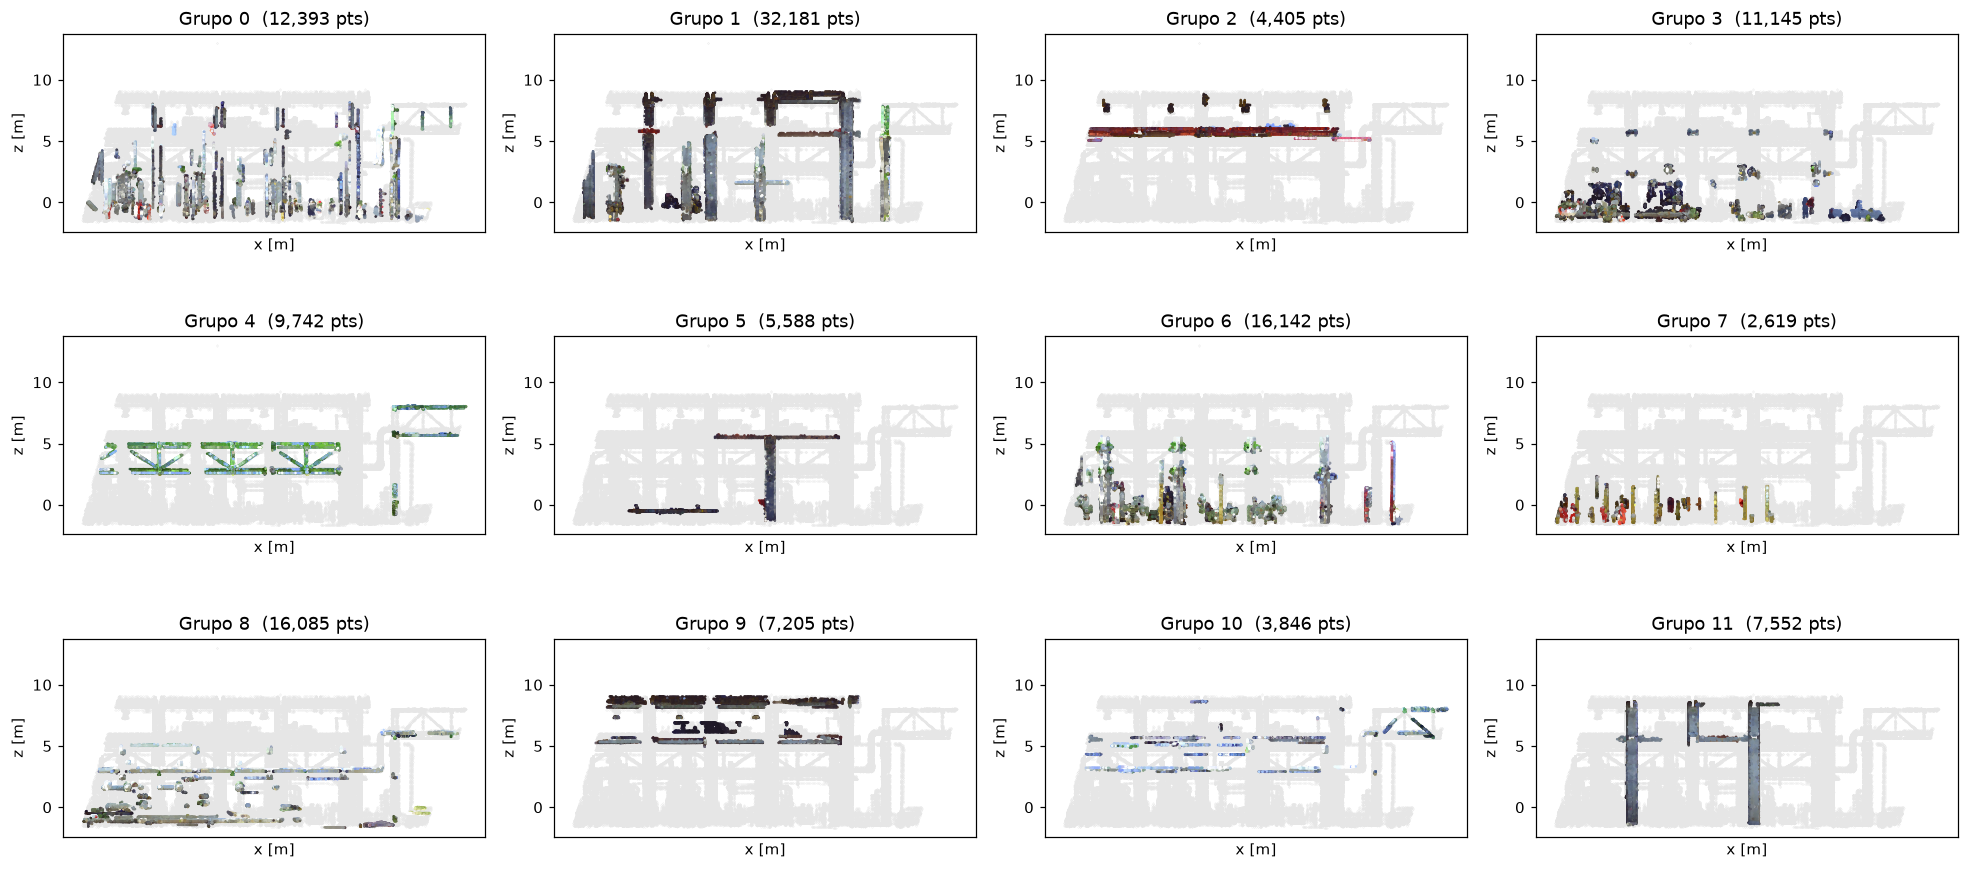

In [46]:
fig, axes = plt.subplots(3, 4, figsize=(18, 8.5))
for k, ax in enumerate(axes.ravel()):
    m = group == k
    view(ax, xyz, "#e6e6e6", s=0.03)
    view(ax, xyz[m], rgb[m], s=0.4, title=f"Grupo {k}  ({summary.loc[k, 'puntos']:,} pts)")
    ax.set_xticks([])
save_fig("fig11_groups")

| Grupo | Contenido | Clase |
|---|---|---|
| 0 | elementos verticales delgados hasta ~2 m | tubería |
| 1 | tramos de columnas de 4 a 8.5 m | columna |
| 2 | vigas principales rojas a ~5.8 m | viga |
| 3 | objetos compactos a nivel del suelo | equipo |
| 4 | vigas verdes con arriostramientos en X | arriostramiento |
| 5 | segmentos grandes de columna, viga y skid | columna |
| 6 | objetos verticales irregulares | equipo |
| 7 | elementos verticales delgados de color | tubería |
| 8 | elementos horizontales lineales bajos | tubería |
| 9 | vigas de cubierta | viga |
| 10 | elementos horizontales lineales a 3–5.5 m | tubería |
| 11 | columnas completas de los pórticos | columna |

Las comprobaciones de la celda siguiente detienen el notebook si la numeración de los grupos cambia.

In [47]:
GROUP_CLASS = {
    0: "tuberia", 1: "columna", 2: "viga", 3: "equipo", 4: "arriostramiento", 5: "columna",
    6: "equipo", 7: "tuberia", 8: "tuberia", 9: "viga", 10: "tuberia", 11: "columna",
}
assert summary.loc[11, "length"] > 8 and summary.loc[11, "axis_vertical"] > 0.9, "grupo 11 ya no son columnas"
assert summary.loc[9, "z_min"] > 7.5, "grupo 9 ya no son vigas de cubierta"
assert summary.loc[3, "z_max"] < 0.5, "grupo 3 ya no son equipos a nivel del suelo"
assert summary.loc[4, "saturation"] > 0.3 and summary.loc[4, "axis_vertical"] < 0.2, "grupo 4 ya no es la estructura verde"

UNLABELED = -1
cls = np.full(len(rest), UNLABELED)
for k, name in GROUP_CLASS.items():
    cls[group == k] = ID[name]
print(f"Puntos con clase: {np.mean(cls >= 0):.0%}")

Puntos con clase: 67%


### Restricciones de contexto para los equipos
Un equipo vertical de más de 3.5 m pasa a columna (ancho > 0.6 m) o a tubería; uno cuyo punto más bajo está a más de 1 m queda sin clase.

In [48]:
seg_df["height"] = seg_df.z_max - seg_df.z_min
is_equipment = seg_df.grupo.map(GROUP_CLASS) == "equipo"
tall = is_equipment & (seg_df.axis_vertical > 0.9) & (seg_df.height > 3.5)
raised = is_equipment & (seg_df.z_min > 1.0) & ~tall

cls[np.isin(seg, seg_df.segment[tall & (seg_df.width > 0.6)])] = ID["columna"]
cls[np.isin(seg, seg_df.segment[tall & (seg_df.width <= 0.6)])] = ID["tuberia"]
cls[np.isin(seg, seg_df.segment[raised])] = UNLABELED
print(f"Equipos altos reclasificados: {tall.sum()} segmentos  |  equipos elevados sin clase: {raised.sum()} segmentos")

Equipos altos reclasificados: 10 segmentos  |  equipos elevados sin clase: 49 segmentos


## 12. Refinamiento y propagación de etiquetas
En columnas y arriostramientos, los puntos de eje horizontal pasan a viga; luego, filtro de moda ($k = 15$) dentro de la estructura.

In [49]:
def knn_vote(src_xyz, src_labels, dst_xyz, k=10):
    _, idx = cKDTree(src_xyz).query(dst_xyz, k=k, workers=-1)
    return mode(src_labels[idx], axis=1).mode

In [50]:
a = f["axis_vertical_80"]
cls[(cls == ID["columna"]) & (a < 0.4)] = ID["viga"]
cls[(cls == ID["arriostramiento"]) & (a < 0.15)] = ID["viga"]

structure = np.isin(cls, [ID["columna"], ID["viga"], ID["arriostramiento"]])
cls[structure] = knn_vote(xyz[structure], cls[structure], xyz[structure], k=15)
class_table(cls[cls >= 0])

,puntos,%
viga,37058,30.2
tuberia,35867,29.2
columna,29835,24.3
equipo,16853,13.7
arriostramiento,3059,2.5


### Propagación
Los puntos sin clase toman la clase mayoritaria de sus 10 vecinos y luego la de su fragmento.

In [51]:
unlabeled = cls == UNLABELED
cls[unlabeled] = knn_vote(xyz[~unlabeled], cls[~unlabeled], xyz[unlabeled], k=10)
for s in np.unique(seg[unlabeled & (seg >= 0)]):
    m = unlabeled & (seg == s)
    cls[m] = np.bincount(cls[m]).argmax()

label = label2.copy()
label[rest] = cls
full_label = np.full(len(cloud), ID["ruido"])
full_label[~noise] = label[inverse]

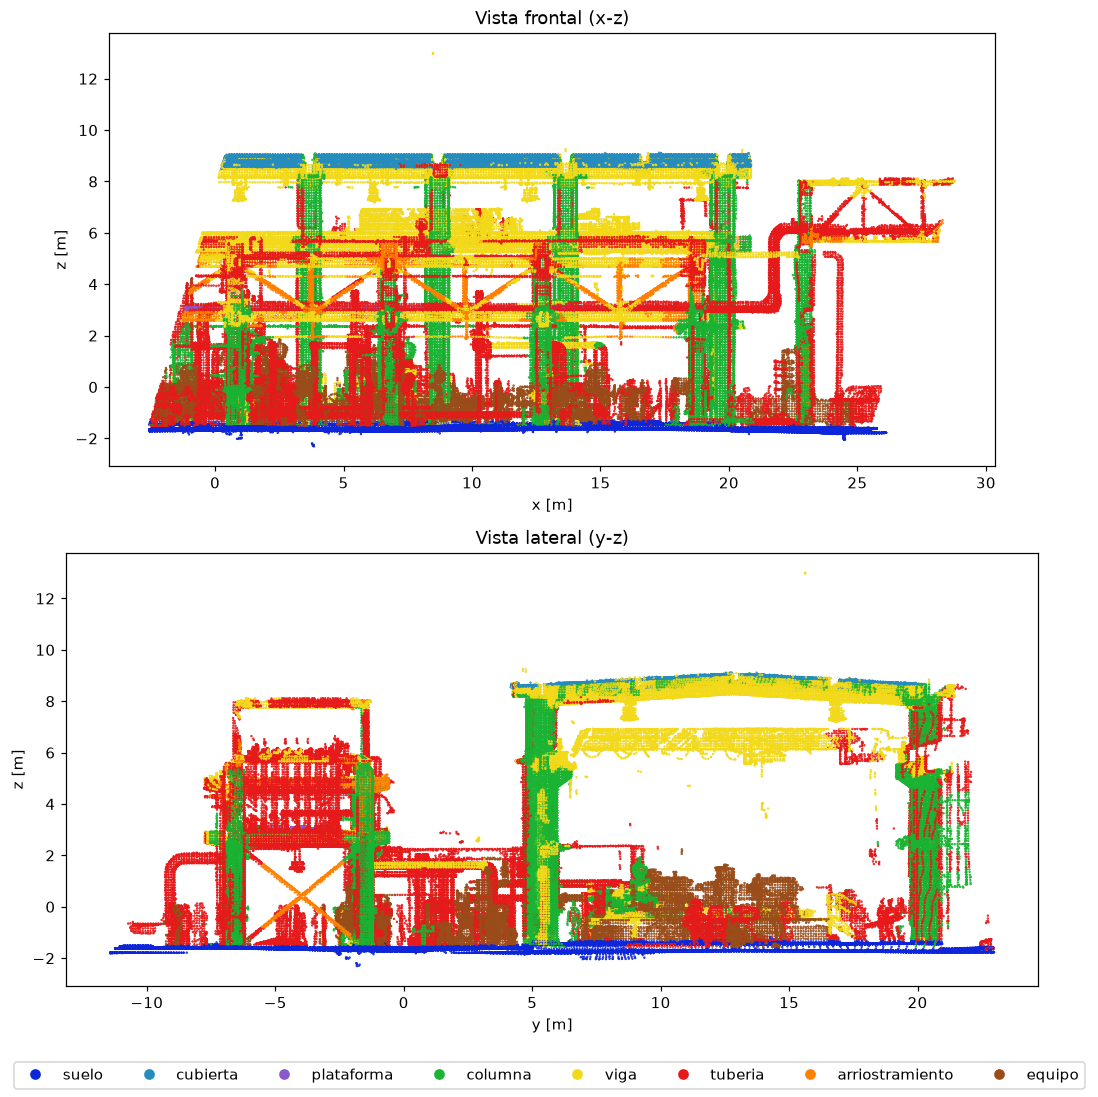

In [52]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))
view(axes[0], reduced.xyz, PALETTE[label], "xz", s=0.3, title="Vista frontal (x-z)")
view(axes[1], reduced.xyz, PALETTE[label], "yz", s=0.3, title="Vista lateral (y-z)")
class_legend(fig, [n for n in NAMES if n not in ("sin_asignar", "ruido")])
save_fig("fig12_final", rect=(0, 0.04, 1, 1))

## 13. Exportación del resultado

In [53]:
save_colored_ply("output/segmentacion_final.ply", cloud.xyz, PALETTE[full_label])
class_table(full_label)

,puntos,%
suelo,481860,29.3
viga,293541,17.8
tuberia,277746,16.9
columna,224778,13.6
cubierta,172916,10.5
equipo,134563,8.2
plataforma,31161,1.9
arriostramiento,27645,1.7
ruido,2811,0.2


### Capturas 3D
Misma vista en perspectiva con el color real y con las clases. Los colores se pasan a espacio lineal porque el renderizador los convierte a sRGB.

In [54]:
R = o3d.visualization.rendering
renderer = R.OffscreenRenderer(1600, 1000)
renderer.scene.view.set_color_grading(R.ColorGrading(R.ColorGrading.Quality.HIGH, R.ColorGrading.ToneMapping.LINEAR))
material = R.MaterialRecord()
material.shader = "defaultUnlit"
material.point_size = 2
center = np.array([13.0, 5.5, 3.0])
eye = center + 34 * np.array([1.2, -1.0, 0.8]) / np.linalg.norm([1.2, -1.0, 0.8])

for name, colors in [("rgb", cloud.rgb), ("clases", PALETTE[full_label])]:
    pc = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(cloud.xyz))
    pc.colors = o3d.utility.Vector3dVector(colors ** 2.2)
    renderer.scene.clear_geometry()
    renderer.scene.add_geometry("nube", pc, material)
    renderer.setup_camera(40, center, eye, [0, 0, 1])
    renderer.render_to_image()
    img = np.asarray(renderer.render_to_image()).copy()
    img[np.abs(img.astype(int) - img[0, 0]).sum(-1) < 12] = 255
    plt.imsave(f"figures/fig13_render_{name}.png", img)